# Malignant vs non-malignant cells in melanoma scRNA-seq

This notebook tells the story of the analysis using the outputs of `scripts/run_pipeline.sh`.
Run the pipeline first. Every number shown here is read from `results/` or `data/processed/`,
and every method choice is explained in [`docs/decisions.md`](../docs/decisions.md).

**Data:** Tirosh et al. 2016 (GEO GSE72056). 4,645 cells from 19 metastatic melanomas,
Smart-seq2, values log2(TPM/10 + 1).

In [1]:
from pathlib import Path

import anndata as ad
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES, FIGURES = ROOT / "results" / "tables", ROOT / "results" / "figures"


def table(name, **kw):
    return pd.read_csv(TABLES / name, sep="\t", **kw)


def figure(name, width=900):
    display(Image(filename=str(FIGURES / name), width=width))

## 1. Quality control

The file has already been normalised (TPM) and filtered by the authors, and it has no
mitochondrial genes. So QC here checks for outliers rather than doing the heavy lifting.
Scrublet needs raw counts and cannot be used. Instead, cells that strongly express both
an immune marker (PTPRC) and melanocyte markers are removed as likely doublets.

In [2]:
table("qc_summary.tsv")

,step,unit,removed,remaining,reason
0,start,cells,0,4645,cells in the deposited file
1,genes detected outlier,cells,0,4645,"outside 1,068 to 15,405 detected genes (median..."
2,immune + melanocyte co-expression,cells,26,4619,PTPRC and PMEL/MLANA/TYR both > 7 log2(TPM/10+...
3,rare genes,genes,1401,22285,detected in fewer than 3 cells (no information...


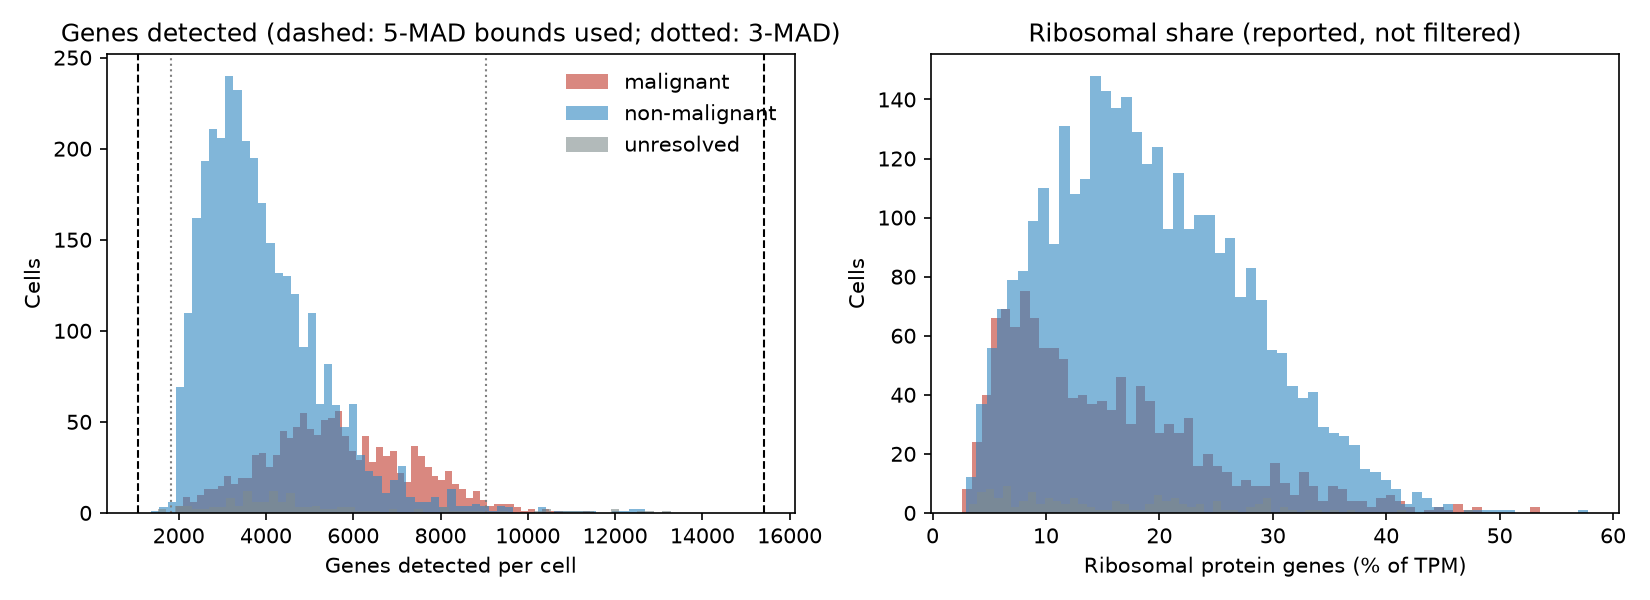

In [3]:
figure("qc_distributions.png")

Malignant cells detect more genes than immune cells. That's why a loose 5-MAD cut-off was
used: a tight upper bound would throw out tumour cells for being large and active.

## 2. Clustering: tumour cells group by patient

20 Leiden clusters. Malignant clusters are almost entirely one patient each, while immune
clusters mix patients. Each tumour has its own genetic changes, but a T cell looks like a
T cell in anyone. So no batch correction is applied.

In [4]:
comp = table("cluster_composition.tsv", index_col=0)
n_cells = comp[["malignant", "non-malignant", "unresolved"]].sum(axis=1)
comp["frac_malignant"] = comp["malignant"] / n_cells
share_mal = comp.loc[comp["frac_malignant"] >= 0.8, "dominant_tumour_share"].median()
share_norm = comp.loc[comp["frac_malignant"] <= 0.2, "dominant_tumour_share"].median()
print(f"Mostly-malignant clusters: median {share_mal:.0%} of cells from one tumour")
print(f"Mostly-normal clusters:    median {share_norm:.0%} of cells from one tumour")

Mostly-malignant clusters: median 99% of cells from one tumour
Mostly-normal clusters:    median 28% of cells from one tumour


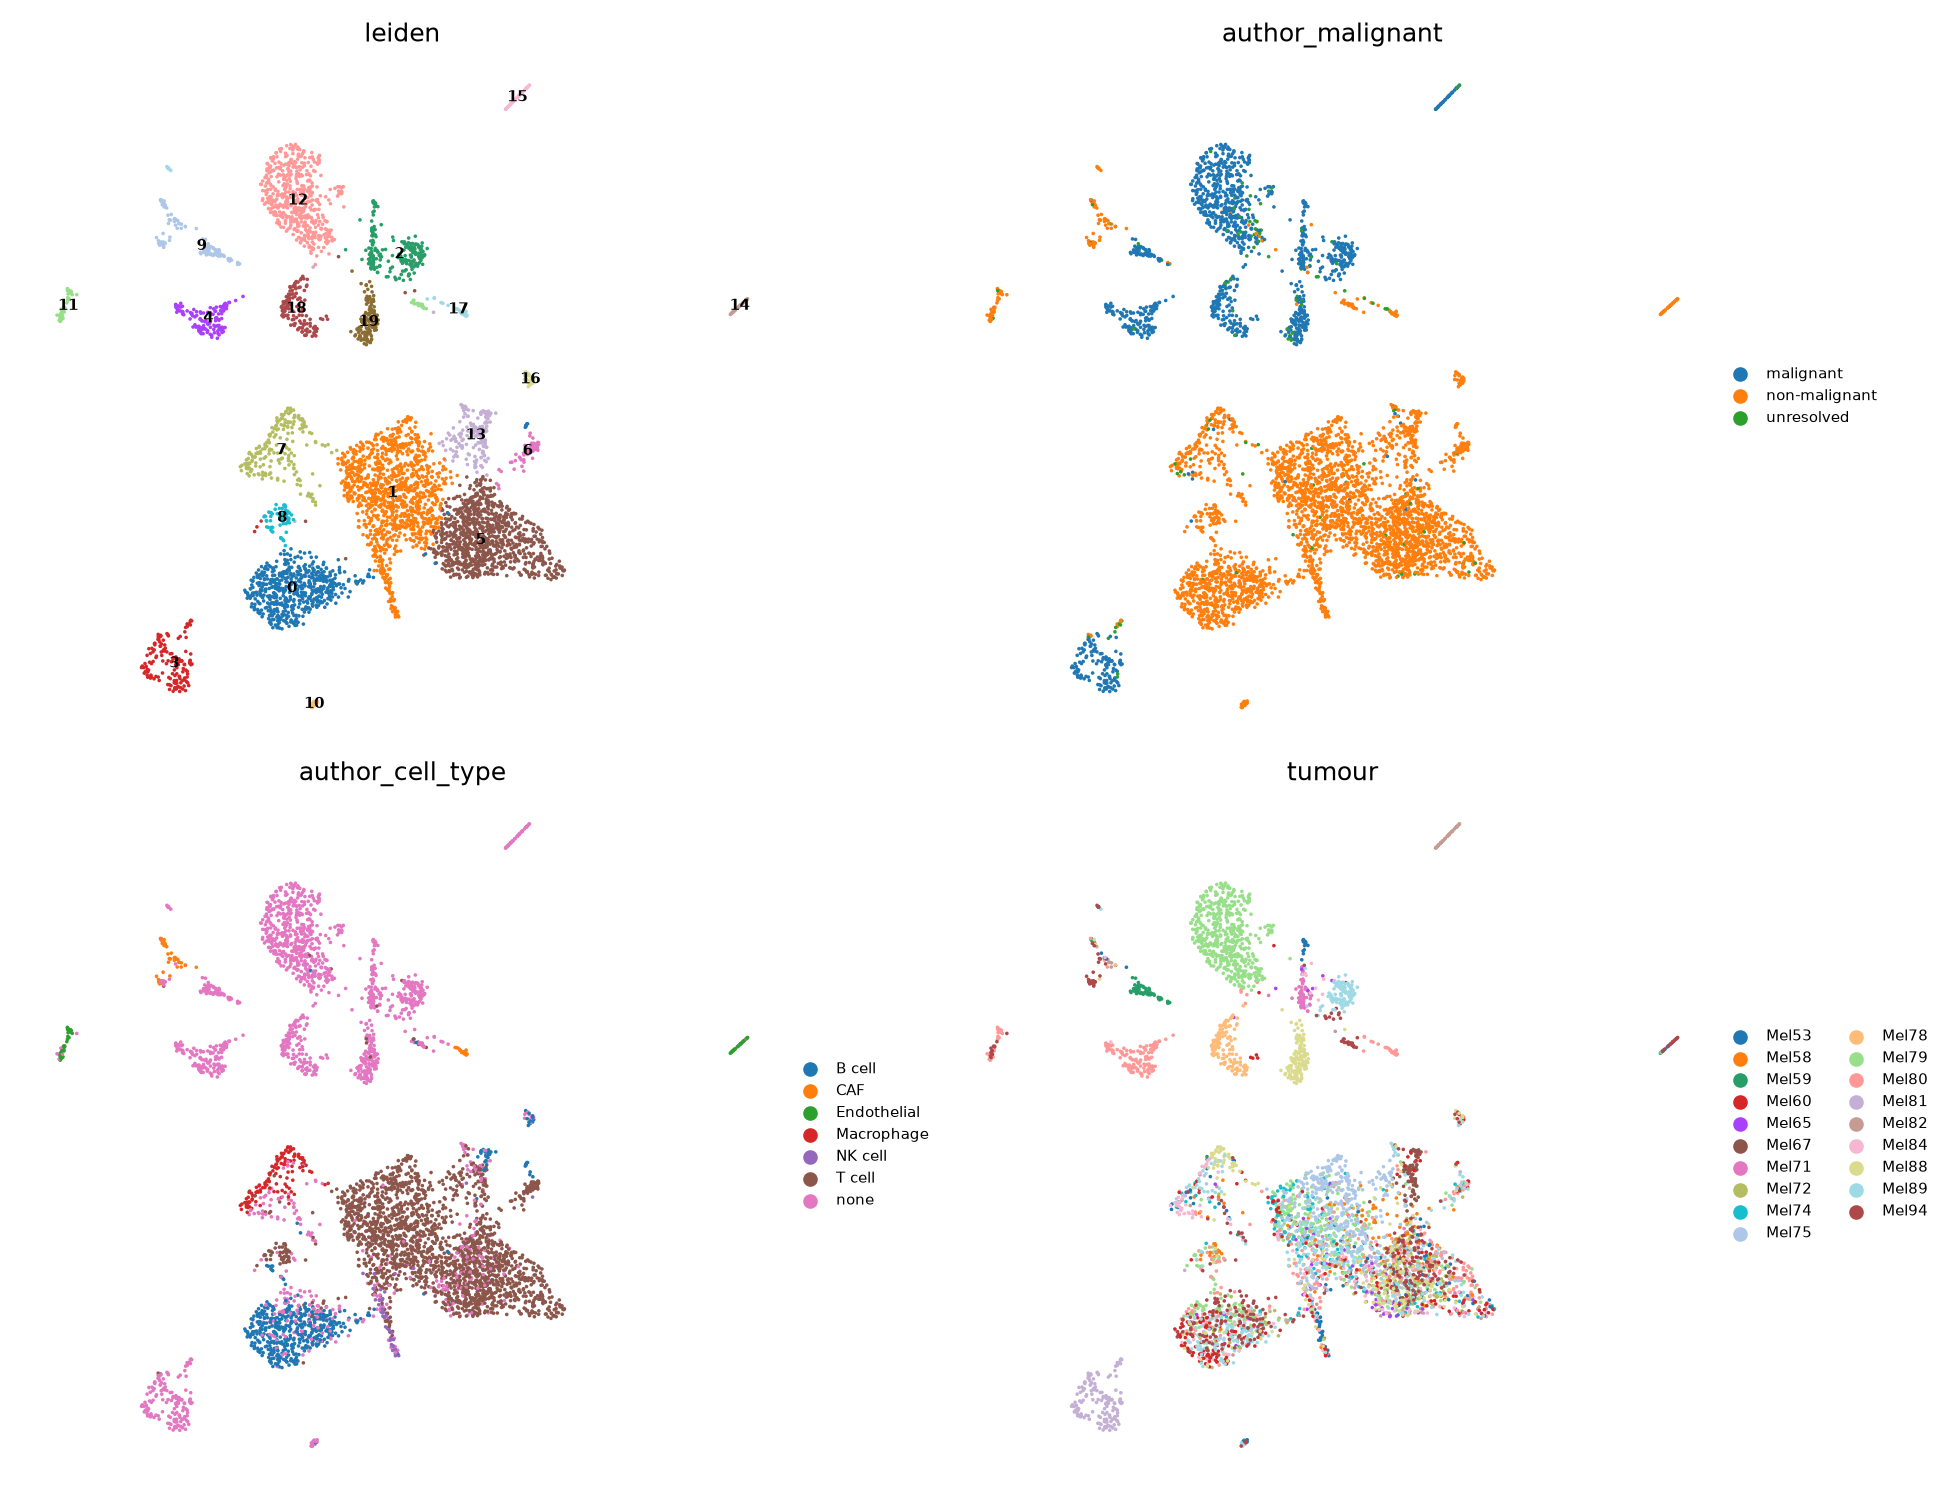

In [5]:
figure("umap_overview.png")

## 3. Cell-type annotation from marker genes

Each cluster is labelled from short lists of textbook markers. Each label is then checked
against the cluster's own top genes from a Wilcoxon test.

In [6]:
ann = table("cluster_annotation.tsv", index_col=0)
ann[["n_cells", "label", "top_score", "top_genes"]].sort_values("label")

,n_cells,label,top_score,top_genes
group,,,,
0,572,B cell,5.64,"MS4A1, CD74, CD79A, HLA-DRA, BANK1, CD37, HLA-..."
17,32,CAF,4.92,"CALD1, TAGLN, MYL9, TPM2, TPM1, PTRF, TPM4, MAP1B"
11,60,Endothelial,3.37,"SDPR, TFPI, PROX1, PDLIM1, CLDN5, IGFBP7, IFIT..."
14,32,Endothelial,5.34,"PLVAP, ELTD1, VWF, ENG, AQP1, CALCRL, COL4A2, ..."
7,197,Macrophage,5.12,"TYROBP, IFI30, AIF1, LYZ, FCER1G, FTL, HLA-DRA..."
18,133,Melanocytic,6.49,"KIT, GSTP1, SCD, PAICS, TUBB4A, MLANA, DCT, OCA2"
12,505,Melanocytic,5.59,"MIA, SERPINE2, S100A6, APOD, MFGE8, NSG1, A2M,..."
4,123,Melanocytic,5.63,"MAGEC2, RCN3, CALU, LGALS1, CAPG, MMP8, KDELR3..."
2,203,Melanocytic,4.97,"LGALS3BP, SNHG16, LMNA, FXYD3, DCT, TFAP2A, SD..."


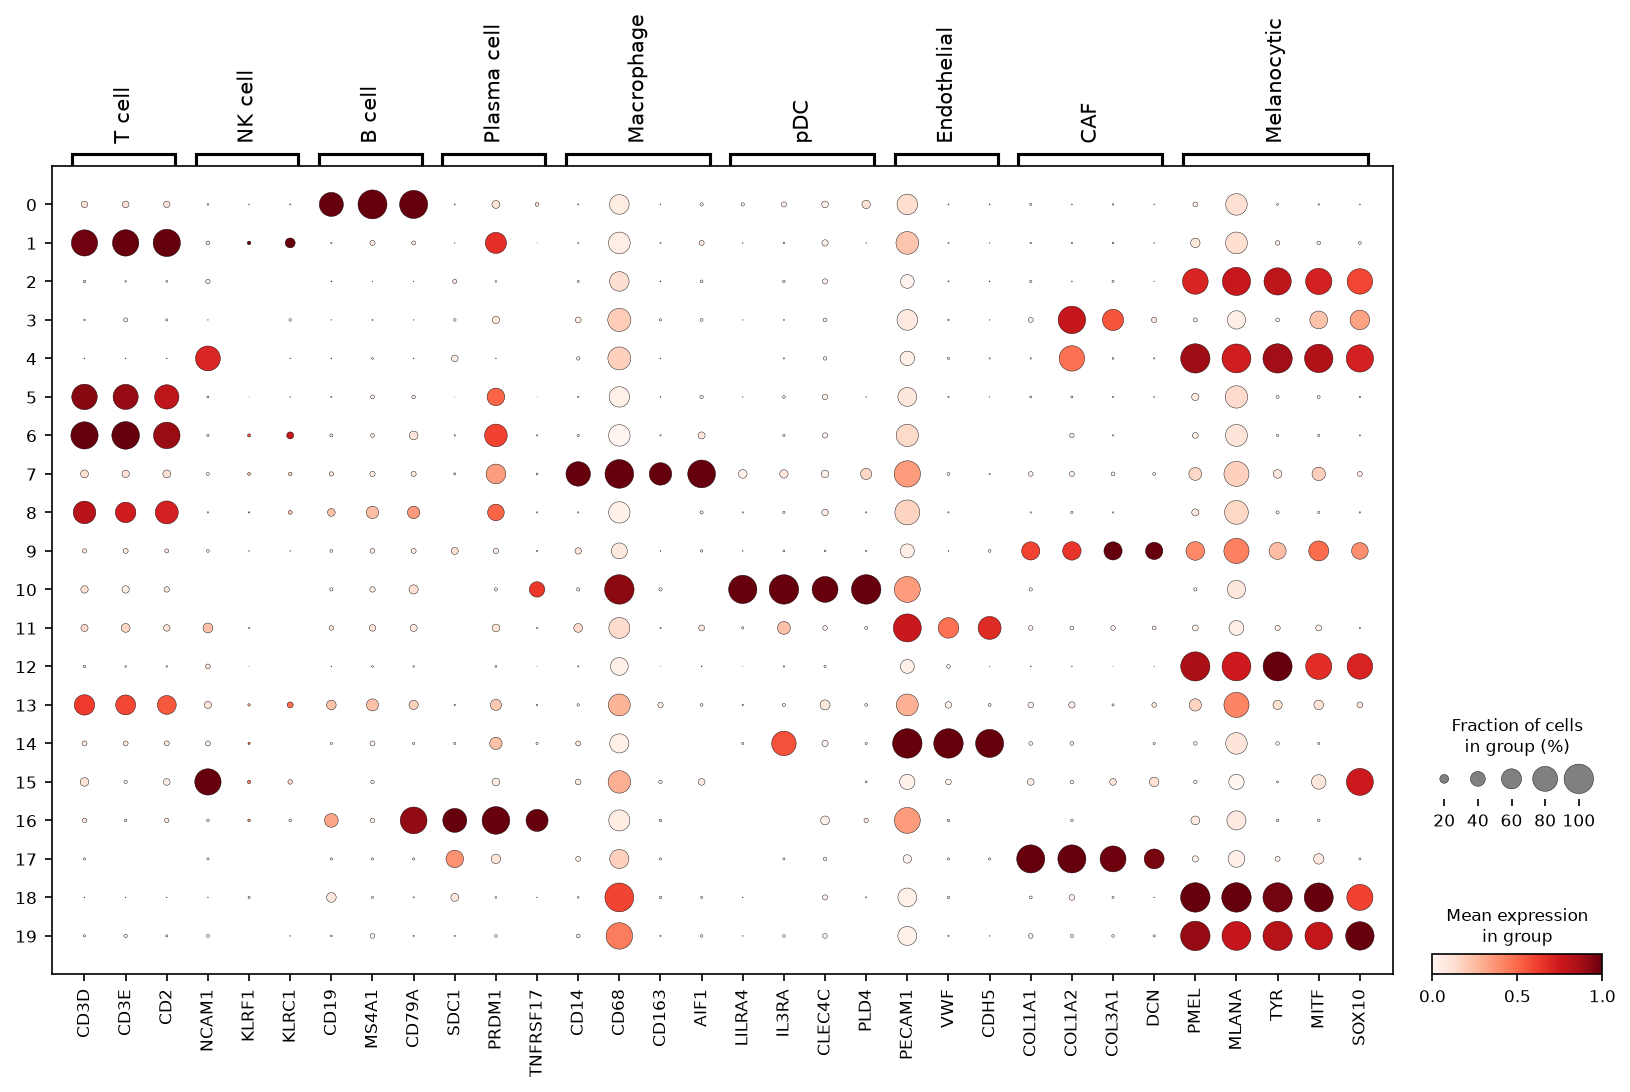

In [7]:
figure("marker_dotplot.png")

In [8]:
cmp = table("annotation_vs_author.tsv", index_col=0)
cmp

,B cell,CAF,Endothelial,Macrophage,Melanocytic,Mixed: CAF / Melanocytic,Plasma cell,T cell,Unclear,pDC
author_cell_type,,,,,,,,,,
B cell,456,0,2,2,1,0,12,41,0,1
CAF,0,18,0,0,0,43,0,0,0,0
Endothelial,0,0,65,0,0,0,0,0,0,0
Macrophage,0,0,0,126,0,0,0,0,0,0
NK cell,0,0,0,0,0,0,0,51,0,0
T cell,13,0,4,11,7,1,0,2004,3,0


Agreement with the author cell types is 93.7% overall. NK cells (0 of 51) are hidden inside
a cytotoxic T-cell cluster, and most CAFs sit in a mixed cluster. Two clusters (3 and 15)
could not be labelled. They turn out to be malignant cells that have switched off the
melanocyte genes, which is why malignancy is called from copy number and not from markers.

## 4. Malignant cells from inferred copy-number variation

infercnvpy averages expression over windows of 100 neighbouring genes, relative to normal
reference cells. Half of our immune/stromal cells are the reference (one baseline per cell
type). The other half is held out to set the thresholds.

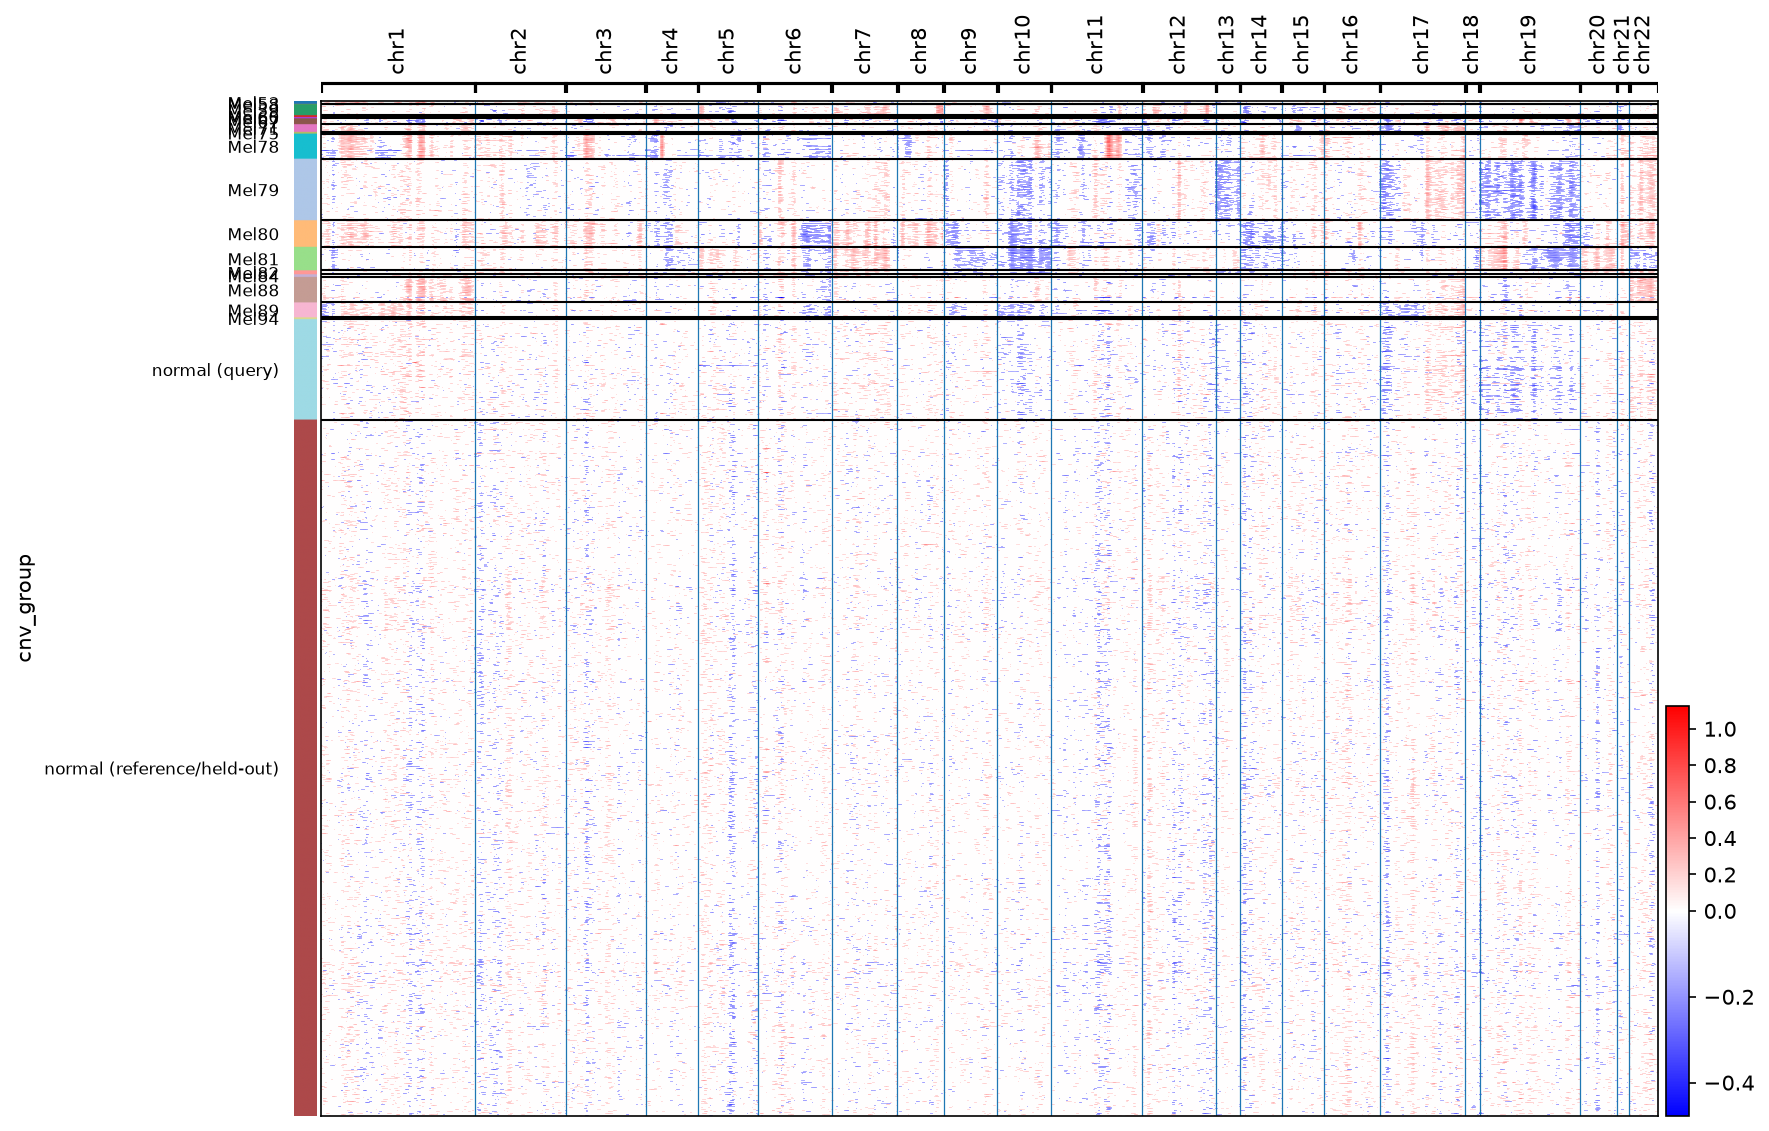

In [9]:
figure("cnv_heatmap.png")

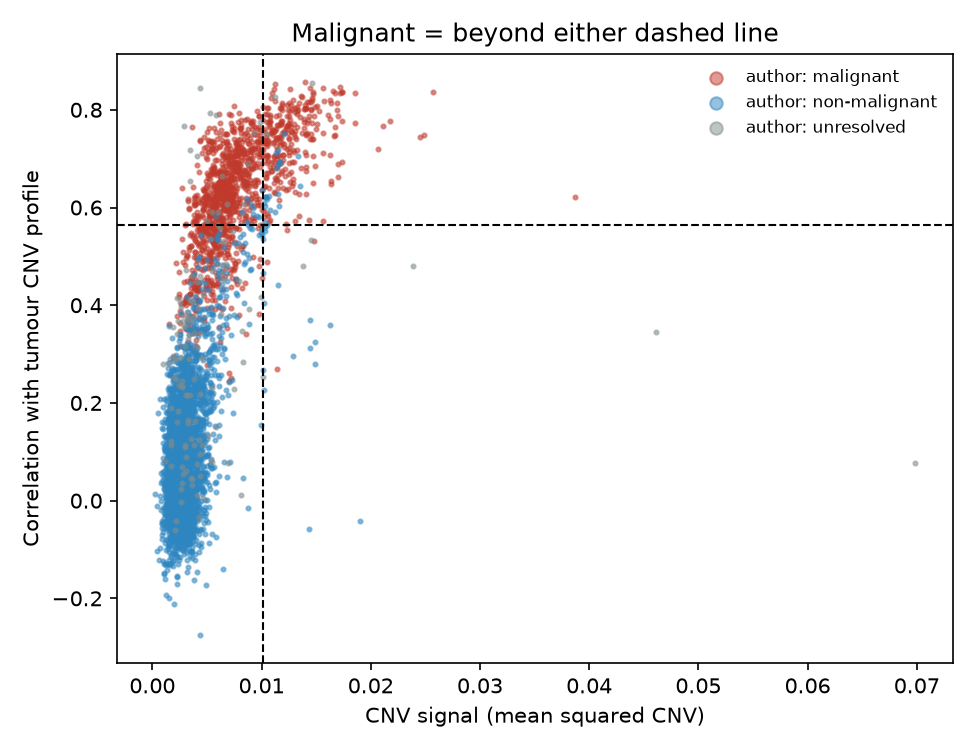

In [10]:
figure("cnv_signal_vs_correlation.png", width=600)

In [11]:
cnv = ad.read_h5ad(ROOT / "data" / "processed" / "tirosh_cnv.h5ad", backed="r")
obs = cnv.obs[cnv.obs["author_malignant"] != "unresolved"]
author = obs["author_malignant"] == "malignant"
ours = obs["cnv_call"] == "malignant"
print(f"Agreement   {(author == ours).mean():.1%}")
print(f"Sensitivity {(author & ours).sum() / author.sum():.1%}")
print(f"Specificity {(~author & ~ours).sum() / (~author).sum():.1%}")
pd.crosstab(cnv.obs["author_malignant"], cnv.obs["cnv_call"])

Agreement   91.5%
Sensitivity 73.3%
Specificity 98.6%


cnv_call,malignant,non-malignant
author_malignant,,
malignant,922,335
non-malignant,46,3184
unresolved,25,107


In [12]:
table("cnv_sensitivity_analysis.tsv")

,reference,window_genes,agreement,sensitivity,specificity,stromal_or_myeloid_called_malignant
0,one per cell type,100,0.915,0.733,0.986,4
1,one per cell type,150,0.940,0.823,0.986,5
2,pooled,100,0.961,0.898,0.985,26
3,pooled,150,0.973,0.946,0.984,27


The stricter setting (per-cell-type reference, first row) is kept on purpose. A pooled
reference finds more tumour cells but also calls fibroblasts malignant, and fibroblasts
express AXL, which would bias the next question.

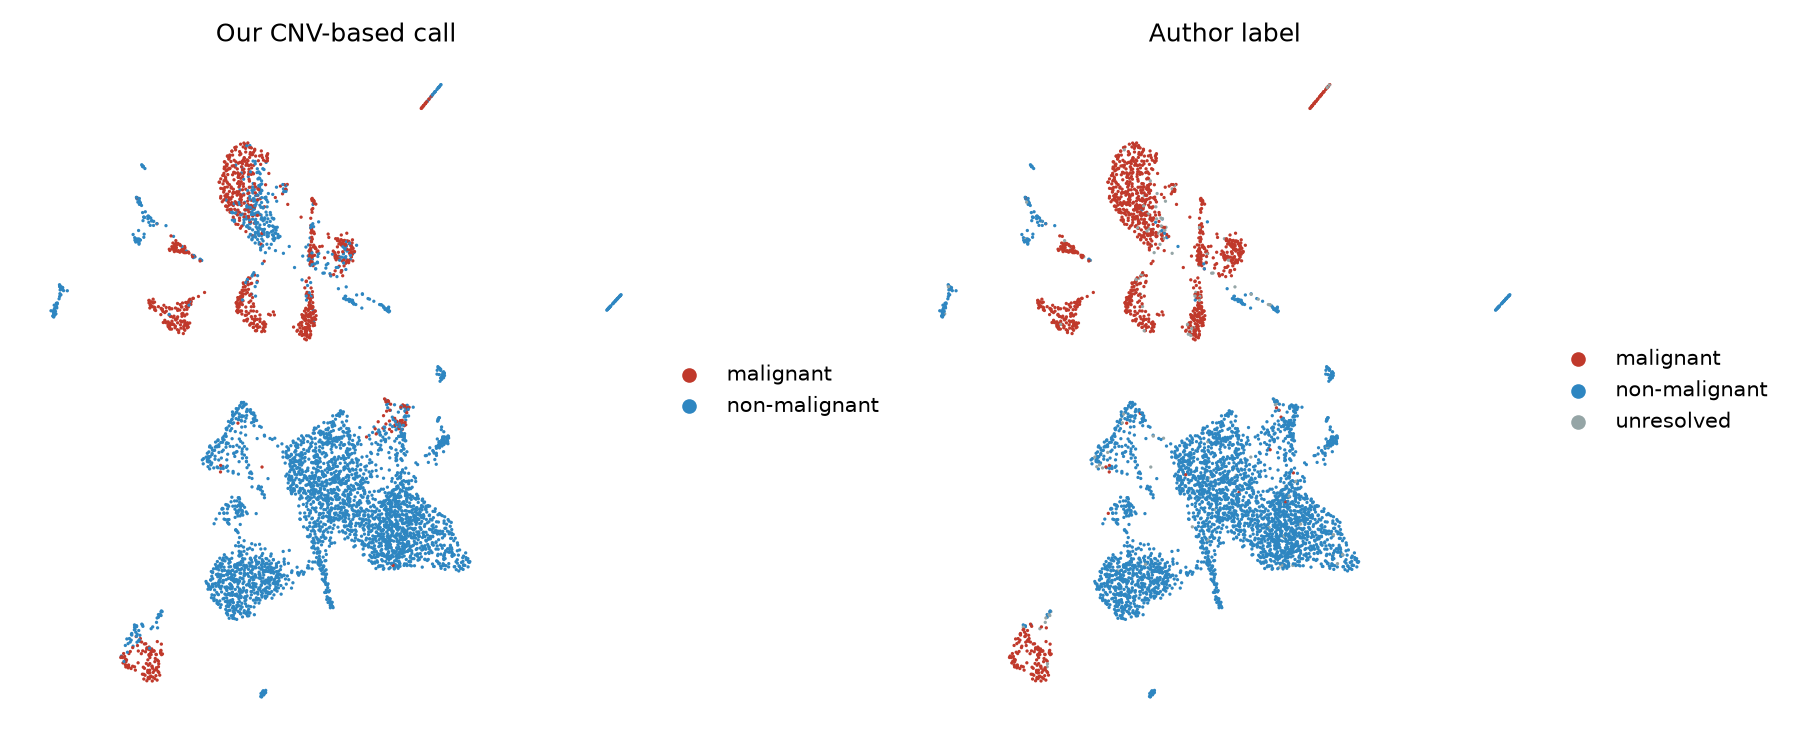

In [13]:
figure("umap_cnv_call.png")

## 5. MITF-high vs AXL-high malignant states

MITF and AXL programmes (50 genes each) are learned on half of the malignant cells and
tested on the other half.

In [14]:
genes = table("programme_genes.tsv")
genes.head(15)

,MITF_programme,AXL_programme
0,PMEL,NGFR
1,MLANA,TNC
2,PLP1,IFITM10
3,GPR143,ITGB3
4,ABCB5,SEMA3B
5,TYR,PTRF
6,APOC2,LIF
7,MOK,LOC401010
8,S100B,GALNT15
9,CTNNB1,FSTL3


In [15]:
table("programmes_per_tumour.tsv", index_col=0).round(2)

,n_malignant,median_MITF_score,median_AXL_score,frac_AXL_dominant,n_held_out,within_rho,within_p
tumour,,,,,,,
Mel78,114,0.31,-0.12,0.09,57,-0.20,0.14
Mel88,114,0.22,-0.34,0.10,57,-0.10,0.46
Mel84,10,0.16,-0.15,0.10,5,NaN,NaN
Mel60,7,0.16,-0.16,0.14,4,NaN,NaN
Mel94,6,-0.14,-0.25,0.17,3,NaN,NaN
Mel80,120,0.24,0.05,0.30,60,-0.44,0.00
Mel65,5,-0.28,-0.26,0.40,3,NaN,NaN
Mel79,280,0.21,0.11,0.42,140,-0.45,0.00
Mel71,35,-0.26,-0.32,0.43,18,0.31,0.21


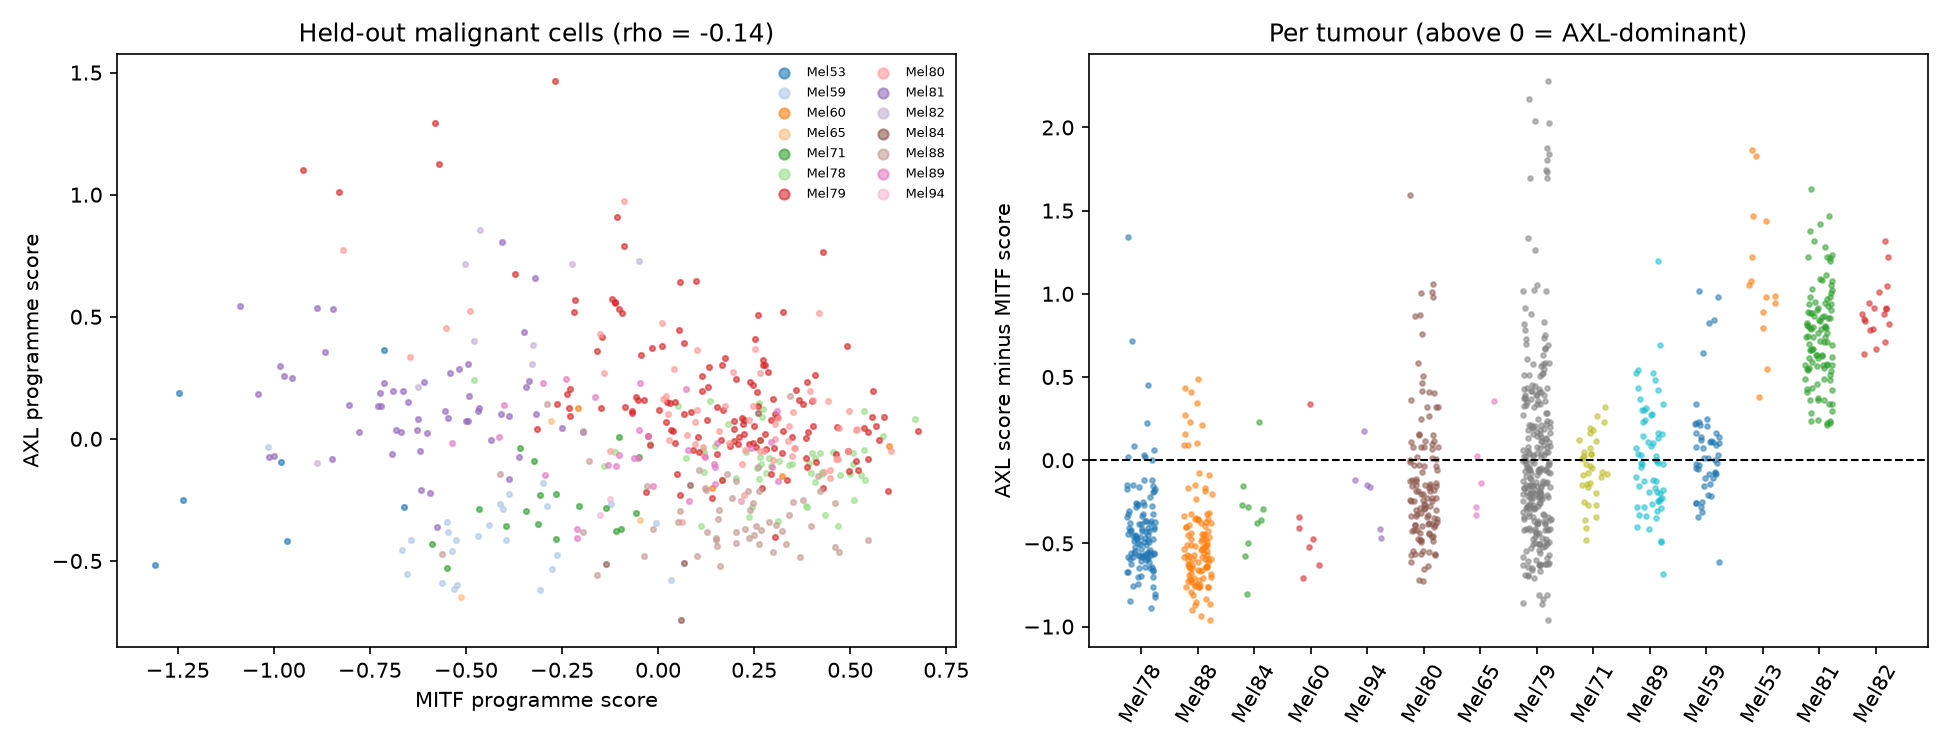

In [16]:
figure("mitf_axl_programmes.png")

The table and figure above use one random split. A single split turned out to be fragile,
so the whole analysis is repeated over 50 splits:

In [17]:
stab = table("programme_split_stability.tsv")
stab[["pooled_rho", "within_rho"]].describe(percentiles=[0.05, 0.5, 0.95]).round(2)

,pooled_rho,within_rho
count,50.00,50.00
mean,-0.17,-0.15
std,0.09,0.07
min,-0.35,-0.30
5%,-0.33,-0.25
50%,-0.17,-0.15
95%,-0.01,-0.03
max,0.06,0.05


In [18]:
frac = stab.filter(like="frac_AXL_").agg(["min", "median", "max"]).T
frac.index = frac.index.str.removeprefix("frac_AXL_")
frac.sort_values("median").round(2)

,min,median,max
Mel94,0.00,0.00,0.67
Mel78,0.02,0.05,0.21
Mel84,0.00,0.10,0.30
Mel88,0.04,0.11,0.39
Mel60,0.14,0.14,0.29
Mel65,0.00,0.20,0.60
Mel71,0.03,0.23,0.69
Mel80,0.11,0.28,0.36
Mel59,0.14,0.28,0.72
Mel89,0.21,0.32,0.52


**Take-home:** tumours differ a lot, and that holds in every split. Mel53, Mel81 and Mel82
are almost entirely AXL-dominant, while Mel78 and Mel88 are mostly MITF-dominant. Within a
tumour, the two programmes are only weakly anti-correlated (median rho = -0.13 across 50
splits, always negative). This fits the existence of both states but gives only modest
support for a strong trade-off inside each tumour. See `docs/decisions.md` (D24) and the
README limitations.